Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-lstm-dolgaya-kratkosrochnaya-pamyat

проблемой RNN слоя является то, что информация о предыдущих тактах быстро затирается, то есть вектор h - это вектор краткосрочной памяти модели. Но часто бывает важно, например, в длинных текстах сохранять контекст, так как связаны могут быть начало и конец.  

В 1997 году была предложена архитектура, учиытвающая это - LSTM

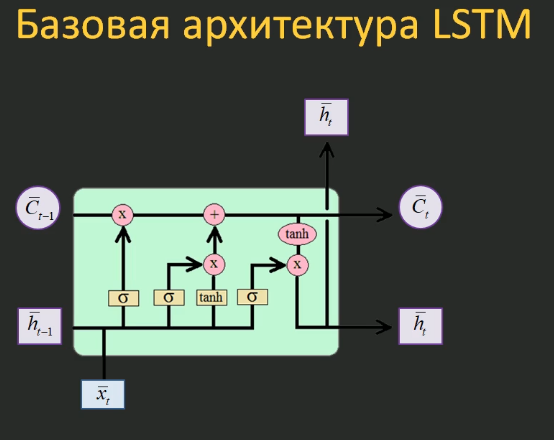

На вход модели подается признаковое описание текущего такта xt, а также вектор скрытого состояния h_t-1. Они конкатенируются (эта операция обозначена как квадратные скобки), умножаются на матрицу весов, складываются с биасом и прогоняются через функцию активаци. В результате вектор ft приобретает вид вектора весов от 0 до 1. Он называется вектором контекста.  
Параллельно в модель поступает вектор контекста C_t-1, который имеет ту же размерность, что и ft. C_t-1 и ft перемножаются, и в результате неважные элементы вектора C_t-1 постепенно зануляются. Так реализовано забывание ненужного

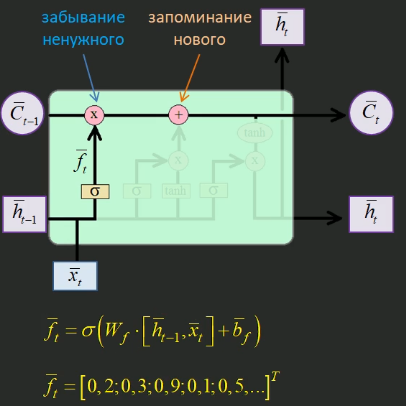

То, что следует запомнить, рассчитывается следующим образом. Рассчитывается оценочный вектор it и вектор Ct того, что нужно запомнить. Они поэлементно перемножаются. В итоге вектор контекста всей ячейки формируется следующим образом (последняя строчка): в первом слагаемом мы забываем лишнее, а во втором наоборот подсвечиваем то, что нужно запомнить

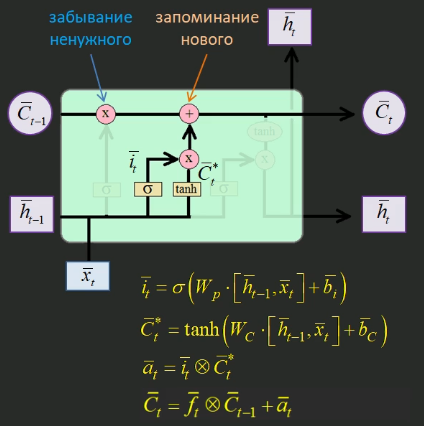

Теперь формируется вектор скрытого состояния ht

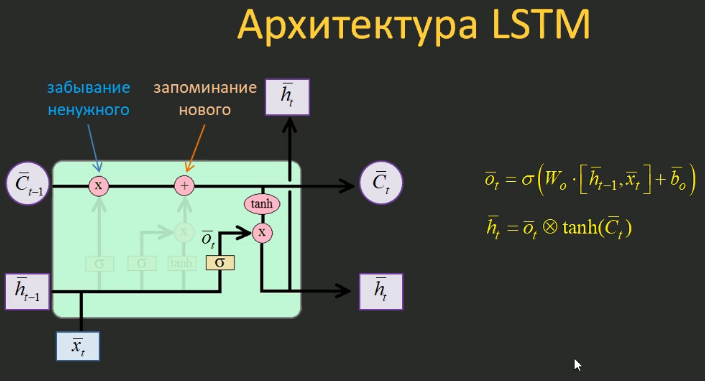

In [1]:
import torch
import torch.nn as nn
 
rnn = nn.LSTM(input_size=10, hidden_size=16, batch_first=True)
 
x = torch.randn(1, 5, 10) # (batch_size, sq_length, d_size)
y, (h, c) = rnn(x)
 
print('y:', y.size()) # так же хранит h с каждого шага
print('h:', h.size())
print('c:', c.size())

y: torch.Size([1, 5, 16])
h: torch.Size([1, 1, 16])
c: torch.Size([1, 1, 16])


Можно сделать сеть двунаправленной

In [2]:
rnn = nn.LSTM(10, 16, batch_first=True, bidirectional=True)
y, (h, c) = rnn(x)

print('y:', y.size())
print('h:', h.size())
print('c:', c.size())

y: torch.Size([1, 5, 32])
h: torch.Size([2, 1, 16])
c: torch.Size([2, 1, 16])


Так как теперь на выходе у модели по сути две пары векторов (h и C), нужно сконкатенировать четыре элемента

In [ ]:
def forward(self, x):
    x, h = self.rnn(x)
    hh = torch.cat((h[0][-2, :, :], h[0][-1, :, :]), dim=1)
    y = self.out(hh)
    return y